# Análisis de Bolsas de Volatilidad para préstamos respaldados con cryptomonedas

## Importamos los Datos y las Funciones

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from utils.volatility_buffer_optimizer import (
    load_price_df,
    compute_required_buffer_distribution,
    find_buffer_for_target_success,
    summarize_for_coin,
)
df = load_price_df("../data/processed/historic_prices.csv") 

## Settupeamos los Parámetros

In [16]:
LTV_INICIAL = 0.50
LTV_LIQUIDACION  = 0.80
VALOR_PRESTAMO_USD = 10_000

## Creamos las distribuciones

La función compute_required_buffer_distribution recibe los datos, la moneda, el LTV, Liquidacion, valor del prestamo y 2 parámetros especiales:

- mode: 2 modos - "end" y "window", que definirá si se verá el préstamo desde inicio a fin o en un horizonte cercano respectivamente. Si se escoge "window" se debe agregar el parámetro window_minutes, donde se tendrá que poner en minutos hasta cuando debe durar el préstamo. Si se escoge "end" corre con todos los datos de inicio a fin.

- start_stride: cada cuantos minutos hace un chequeo, si se pone 1, entonces cad aminuto revisa la actualización de precio, si se pone 60, entonces cada hora, etc. 

Esto regresa un df con la fecha de inicio

### Para BTC

In [17]:
dist_btc = compute_required_buffer_distribution(
    price_df=df,
    coin="BTC",
    init_ltv=LTV_INICIAL,
    liq_ltv=LTV_LIQUIDACION,
    principal_usd=VALOR_PRESTAMO_USD,
    mode="end",
    start_stride=1
)
print(dist_btc.shape)
dist_btc

(2359028, 6)


,start_ts,p0,pmin,buffer_pct_of_init_collateral,buffer_coins,buffer_usd_at_p0
0,2021-01-01 00:01:00,29009.91,15513.84,0.168711,0.116313,3374.217795
1,2021-01-01 00:02:00,28989.30,15513.84,0.167881,0.115822,3357.611655
2,2021-01-01 00:03:00,28982.69,15513.84,0.167614,0.115665,3352.285765
3,2021-01-01 00:04:00,28975.65,15513.84,0.167331,0.115497,3346.613411
4,2021-01-01 00:05:00,28937.11,15513.84,0.165778,0.114578,3315.560493
...,...,...,...,...,...,...
2359023,2025-06-30 23:54:00,107104.11,107071.65,0.000000,0.000000,0.000000
2359024,2025-06-30 23:55:00,107093.34,107071.65,0.000000,0.000000,0.000000
2359025,2025-06-30 23:56:00,107071.65,107071.65,0.000000,0.000000,0.000000
2359026,2025-06-30 23:57:00,107085.99,107085.99,0.000000,0.000000,0.000000


### Para ETH

In [18]:
dist_eth = compute_required_buffer_distribution(
    price_df=df,
    coin="ETH",
    init_ltv=LTV_INICIAL,
    liq_ltv=LTV_LIQUIDACION,
    principal_usd=VALOR_PRESTAMO_USD,
    mode="end",            
    start_stride=1
)
print(dist_eth.shape)
dist_eth

(2359028, 6)


,start_ts,p0,pmin,buffer_pct_of_init_collateral,buffer_coins,buffer_usd_at_p0
0,2021-01-01 00:01:00,738.74,715.22,0.0,0.0,0.0
1,2021-01-01 00:02:00,737.82,715.22,0.0,0.0,0.0
2,2021-01-01 00:03:00,737.43,715.22,0.0,0.0,0.0
3,2021-01-01 00:04:00,736.89,715.22,0.0,0.0,0.0
4,2021-01-01 00:05:00,735.69,715.22,0.0,0.0,0.0
...,...,...,...,...,...,...
2359023,2025-06-30 23:54:00,2486.10,2484.85,0.0,0.0,0.0
2359024,2025-06-30 23:55:00,2485.94,2484.85,0.0,0.0,0.0
2359025,2025-06-30 23:56:00,2484.85,2484.85,0.0,0.0,0.0
2359026,2025-06-30 23:57:00,2485.56,2485.47,0.0,0.0,0.0


In [19]:
buf99_pct_btc = find_buffer_for_target_success(dist_btc, q=0.99, metric="buffer_pct_of_init_collateral")
buf99_pct_eth = find_buffer_for_target_success(dist_eth, q=0.99, metric="buffer_pct_of_init_collateral")
print("BTC buffer pct for 99% success:", buf99_pct_btc)
print("ETH buffer pct for 99% success:", buf99_pct_eth)

BTC buffer pct for 99% success: 1.518650141583257
ETH buffer pct for 99% success: 2.1544694451655135


In [20]:
buf90_pct_btc = find_buffer_for_target_success(dist_btc, q=0.90, metric="buffer_pct_of_init_collateral")
buf90_pct_eth = find_buffer_for_target_success(dist_eth, q=0.90, metric="buffer_pct_of_init_collateral")
print("BTC buffer pct for 90% success:", buf90_pct_btc)
print("ETH buffer pct for 90% success:", buf90_pct_eth)

BTC buffer pct for 90% success: 0.9658022288485639
ETH buffer pct for 90% success: 1.2667192420121216


In [21]:
summary_btc = summarize_for_coin(
    price_df=df,
    coin="BTC",
    init_ltv=LTV_INICIAL,
    liq_ltv=LTV_LIQUIDACION,
    principal_usd=VALOR_PRESTAMO_USD,
    mode="end",
    window_minutes=365*1440,
    start_stride=1,
    target_q=0.99
)
summary_btc


{'coin': 'BTC',
 'mode': 'end',
 'window_minutes': nan,
 'init_ltv': 0.5,
 'liq_ltv': 0.8,
 'target_q': 0.99,
 'buffer_pct_of_init_collateral@q': 1.518650141583257,
 'buffer_coins@q (using median p0)': 0.7093393457736508,
 'buffer_usd_at_p0@q': 30373.002831665137,
 'n_starts': 2359028}

In [22]:
summary_eth = summarize_for_coin(
    price_df=df,
    coin="ETH",
    init_ltv=LTV_INICIAL,
    liq_ltv=LTV_LIQUIDACION,
    principal_usd=VALOR_PRESTAMO_USD,
    mode="end",
    start_stride=1,
    target_q=0.99
)
summary_eth

{'coin': 'ETH',
 'mode': 'end',
 'window_minutes': nan,
 'init_ltv': 0.5,
 'liq_ltv': 0.8,
 'target_q': 0.99,
 'buffer_pct_of_init_collateral@q': 2.1544694451655135,
 'buffer_coins@q (using median p0)': 18.864765819357245,
 'buffer_usd_at_p0@q': 43089.38890331027,
 'n_starts': 2359028}

# Gráficas

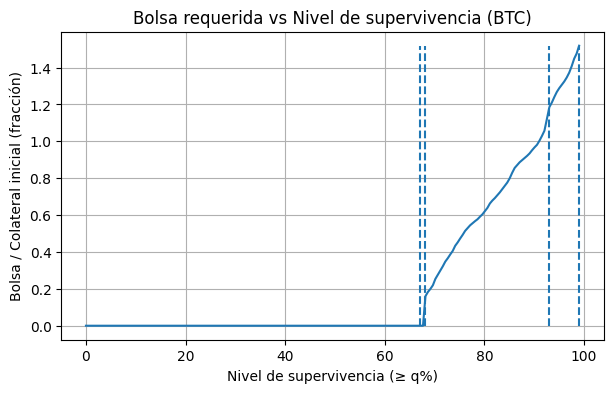

q=0.67 → bolsa=0.0000 (fracción del colateral inicial)
q=0.68 → bolsa=0.1038 (fracción del colateral inicial)
q=0.93 → bolsa=1.1843 (fracción del colateral inicial)
q=0.99 → bolsa=1.5187 (fracción del colateral inicial)


In [23]:
# Serie limpia (sin inf/NaN)
s = pd.Series(dist_btc["buffer_pct_of_init_collateral"]).replace([np.inf, -np.inf], np.nan).dropna()

# Curva de cuantiles: % de supervivencia (q) vs bolsa requerida (en % del colateral inicial)
q_grid = np.linspace(0.0, 0.99, 200)  # del 0% al 99%
y = s.quantile(q_grid)

plt.figure(figsize=(7,4))
plt.plot(q_grid * 100, y)                    # eje X en porcentaje (0–99)
plt.vlines([67, 68, 93, 99], ymin=0, ymax=max(y), linestyles="dashed")
plt.title("Bolsa requerida vs Nivel de supervivencia (BTC)")
plt.xlabel("Nivel de supervivencia (≥ q%)")
plt.ylabel("Bolsa / Colateral inicial (fracción)")
plt.grid(True)
plt.show()

# Valores puntuales que te interesan
for q in [0.67, 0.68, 0.93, 0.99]:
    print(f"q={q:.2f} → bolsa={s.quantile(q):.4f} (fracción del colateral inicial)")

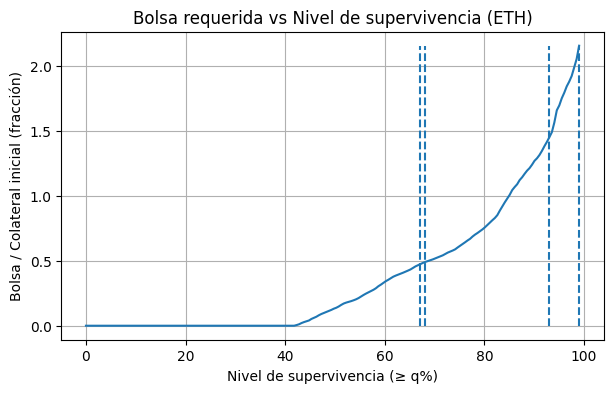

q=0.67 → bolsa=0.4718 (fracción del colateral inicial)
q=0.68 → bolsa=0.4891 (fracción del colateral inicial)
q=0.93 → bolsa=1.4485 (fracción del colateral inicial)
q=0.99 → bolsa=2.1545 (fracción del colateral inicial)


In [24]:
# Para ETH
s_eth = pd.Series(dist_eth["buffer_pct_of_init_collateral"]).replace([np.inf, -np.inf], np.nan).dropna()

# Curva de cuantiles: % de supervivencia (q) vs bolsa requerida (en % del colateral inicial)
q_grid = np.linspace(0.0, 0.99, 200)  # del 0% al 99%
y_eth = s_eth.quantile(q_grid)

plt.figure(figsize=(7,4))
plt.plot(q_grid * 100, y_eth)                    # eje X en porcentaje (0–99)
plt.vlines([67, 68, 93, 99], ymin=0, ymax=max(y_eth), linestyles="dashed")
plt.title("Bolsa requerida vs Nivel de supervivencia (ETH)")
plt.xlabel("Nivel de supervivencia (≥ q%)")
plt.ylabel("Bolsa / Colateral inicial (fracción)")
plt.grid(True)
plt.show()

# Valores puntuales que te interesan
for q in [0.67, 0.68, 0.93, 0.99]:
    print(f"q={q:.2f} → bolsa={s_eth.quantile(q):.4f} (fracción del colateral inicial)")

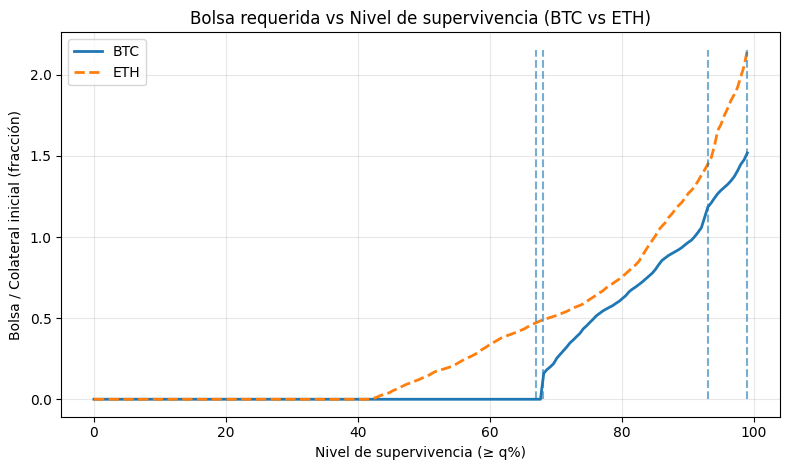

   q  BTC_bolsa(fracción)  ETH_bolsa(fracción)  DIF (BTC-ETH)
0.67             0.000000             0.471821      -0.471821
0.68             0.103779             0.489058      -0.385279
0.93             1.184267             1.448486      -0.264219
0.99             1.518650             2.154469      -0.635819


In [25]:
s_btc = pd.Series(dist_btc["buffer_pct_of_init_collateral"]).replace([np.inf, -np.inf], np.nan).dropna()
s_eth = pd.Series(dist_eth["buffer_pct_of_init_collateral"]).replace([np.inf, -np.inf], np.nan).dropna()


q_grid = np.linspace(0.0, 0.99, 200)          
y_btc = s_btc.quantile(q_grid)
y_eth = s_eth.quantile(q_grid)


plt.figure(figsize=(8,4.8))
plt.plot(q_grid*100, y_btc, label="BTC", linewidth=2)
plt.plot(q_grid*100, y_eth, label="ETH", linewidth=2, linestyle="--")

marks_pct = [67, 68, 93, 99]
ymax = float(max(np.nanmax(y_btc), np.nanmax(y_eth)))
for m in marks_pct:
    plt.vlines(m, ymin=0, ymax=ymax, linestyles="dashed", alpha=0.6)

plt.title("Bolsa requerida vs Nivel de supervivencia (BTC vs ETH)")
plt.xlabel("Nivel de supervivencia (≥ q%)")
plt.ylabel("Bolsa / Colateral inicial (fracción)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# --- Valores puntuales lado a lado ---
qs = [0.67, 0.68, 0.93, 0.99]
rows = []
for q in qs:
    rows.append({
        "q": q,
        "BTC_bolsa(fracción)": s_btc.quantile(q),
        "ETH_bolsa(fracción)": s_eth.quantile(q),
        "DIF (BTC-ETH)": s_btc.quantile(q) - s_eth.quantile(q)
    })
df_marks = pd.DataFrame(rows)
print(df_marks.to_string(index=False))
